# Synthetic Reading of "The Yellow Wallpaper"

**Author:** Vaisnavi Sainath, Humanities and Social Sciences, IIT (ISM) Dhanbad. **Semester:** Monsoon Semester 2026.

This notebook follows the seven steps of synthetic reading: partial reading, initial impression, text upload, query generation, targeted extraction, computation and visualisation, and interpretation. It works on Charlotte Perkins Gilman's story through **feminist standpoint epistemology** and **the medical gaze**.

**How to run it.** Put `corpus.txt`, `partial_reading.txt`, `prompt.txt` and `Theme_JSON.py` in the same folder as this notebook, then choose *Run all*. In Google Colab, the first cell asks you to upload any file that is missing.

## Setup

This is not one of the seven steps. It loads the tools, makes an `outputs` folder, and checks that the four project files are present.

In [1]:
import os, re, json
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("outputs", exist_ok=True)
FILES = ["corpus.txt", "partial_reading.txt", "prompt.txt", "Theme_JSON.py"]
missing = [f for f in FILES if not os.path.exists(f)]
if missing:
    try:
        from google.colab import files
        print("Upload these files now:", missing)
        for name, data in files.upload().items():
            open(name, "wb").write(data)
    except ImportError:
        raise FileNotFoundError(f"Put these files next to the notebook: {missing}")
print("Setup done")

Setup done


# STEP 1: Partial Reading

**What the step requires.** Read the text partially after dividing it equally. Read the first, the middle or the last, or a random 20% of the lines of each part, to form an initial understanding without reading the whole text.

**What is done.** The cleaned story is divided into three equal parts by sentence count. From each part a block of 20% of that part's words (rounded up to the end of a sentence) is read: the **first** block of Part 1, a **random** block of Part 2 (random seed 42, so the same block is chosen every time) and the **last** block of Part 3. The blocks are saved in `partial_reading.txt`. The cell below cleans the story, regenerates the blocks, checks that they match the file, and reports how much of the story was read.

In [2]:
def K(s):
    """Letters and digits only, lower case: makes matching immune to line breaks, hyphens and quote marks."""
    return re.sub(r"[^a-z0-9]", "", s.lower())

OCR_FIX = {"111 spite": "in spite", "perltaps": "perhaps", "per/zaps": "perhaps", "wall-p3.per": "wall-paper",
           "wall-pa per": "wall-paper", "evell": "even", "T is very seldom": "It is very seldom",
           'P""ople': "people", "hall s": "halls"}
raw = open("corpus.txt", encoding="utf-8", errors="ignore").read()
rawfix = raw
for bad, good in OCR_FIX.items():
    rawfix = rawfix.replace(bad, good)
RAWK = K(rawfix)                                                 # raw scan with OCR fixes, letters only (used in Step 5)

def clean_story(r):
    """Step 3 cleaning, defined here because Step 1 reads the cleaned text."""
    t = re.sub("\u00ad\\s*\n\\s*", "", r)                      # rejoin words split across lines
    lines = t.split("\n")[3:]                                    # drop epigraph, title and byline
    keep = [l for l in lines
            if not re.search(r"WALL.?PA|^[\s*\u2022\u00b7\u00a5.\d]*$|^\s*\d+\.\d+\.\d+", l)]   # headers, page numbers, ornaments
    out = re.sub(r"\s+", " ", " ".join(keep)).strip()
    for bad, good in OCR_FIX.items():
        out = out.replace(bad, good)
    return out

text = clean_story(raw)
words = re.findall(r"[A-Za-z']+", text)

def choose_blocks(text, share=0.20, seed=42):
    import random
    sents = re.split(r"(?<=[.!?])\s+(?=[\"'A-Z])", text)
    wc = [len(re.findall(r"[A-Za-z']+", x)) for x in sents]
    n = len(sents); size = n // 3
    blocks = []
    for i, (a, b) in enumerate([(0, size), (size, 2 * size), (2 * size, n)]):
        target = share * sum(wc[a:b])                            # 20% of this part's words
        def end_from(st):
            tot = 0
            for j in range(st, b):
                tot += wc[j]
                if tot >= target:
                    return j + 1
        if i == 0:                                               # Part 1: first block
            st = a
        elif i == 1:                                             # Part 2: random block
            st = random.Random(seed).choice([x for x in range(a, b) if end_from(x)])
        else:                                                    # Part 3: last block
            tot, st = 0, b
            while tot < target:
                st -= 1; tot += wc[st]
        en = end_from(st) if i < 2 else b
        blocks.append((a, b, st, en, " ".join(sents[st:en]), sum(wc[st:en])))
    return sents, blocks

sents, blocks = choose_blocks(text)
pr = open("partial_reading.txt", encoding="utf-8").read()
labels = ["first block", "random block (seed 42)", "last block"]
for i, (a, b, st, en, blk, nw) in enumerate(blocks):
    part_words = sum(len(re.findall(r"[A-Za-z']+", x)) for x in sents[a:b])
    print(f"Part {i+1}, {labels[i]}: sentences {st+1}-{en} of {a+1}-{b}, {nw} words = {nw/part_words*100:.1f}% of the part; in partial_reading.txt: {blk in pr}")
    print("   starts:", blk[:110], "...")
read = sum(x[5] for x in blocks)
print(f"\nRead {read} of {len(words)} words = {read/len(words)*100:.1f}% of the story")

Part 1, first block: sentences 1-25 of 1-124, 460 words = 20.0% of the part; in partial_reading.txt: True
   starts: It is very seldom that mere ordinary people like John and myself secure ancestral halls for the summer. A colo ...
Part 2, random block (seed 42): sentences 206-231 of 125-248, 438 words = 20.0% of the part; in partial_reading.txt: True
   starts: When the sun shoots in through the east window - I always watch for that first long, straight ray - it changes ...
Part 3, last block: sentences 345-372 of 249-372, 367 words = 21.1% of the part; in partial_reading.txt: True
   starts: I don't like to look out of the windows even - there are so many of those creeping women, and they creep so fa ...

Read 1265 of 6225 words = 20.3% of the story


# STEP 2: Initial Impression, Positionality and Statements to Prove

**What the step requires.** A reader-oriented approach in which the reader's own situation shapes the impression. It is a phenomenography: the meaning of the text appears when it is read by a reader with a lived experience. The reader then situates themselves as a researcher with reflexivity and chooses a research problem and frameworks.

**What is done.** The cell prints the impression, research problem and frameworks I wrote after the partial reading (from `partial_reading.txt`). It then holds my positionality, which I fill in, and three statements to prove, which are written **before** any counting.

In [3]:
step2 = pr.split("STEP 2")[1] if "STEP 2" in pr else ""
print(step2.split("======")[-1].strip())

POSITIONALITY = {
    "background": "",        # who you are as a reader: language, region, course, anything relevant to this story
    "noticed_first": "",     # what you noticed first in the story, and why
    "might_overlook": "",    # what your background might make you overlook
}
print("\nPOSITIONALITY")
for k, v in POSITIONALITY.items():
    print(f"- {k}: {v or '(still to be written)'}")

THEMES = {
    "confinement": {"label": "Domestic Confinement & Patriarchal Control",
        "definition": "Rooms, rules and people that restrict the narrator's movement or voice, above all the nursery with barred windows and John's authority.",
        "pattern": r"nursery|barred|\bbars\b|\bgate|locked|\bkey\b|forbidden|not hear of|hardly lets|laughs at me"},
    "medical": {"label": "The Medical Gaze & The Rest Cure",
        "definition": "Medical authority and vocabulary: physician, diagnosis, tonics, the rest cure, nervous or hysterical labels applied to the narrator.",
        "pattern": r"physician|doctor|phosphates|phosphites|tonics|nervous|hysterical|rest cure|treatment|medicine|\bsick\b|get well|exercise"},
    "art": {"label": "Repression of Female Artistic Expression",
        "definition": "The narrator's wish to write and imagine, and the prohibition of it as harmful to her recovery.",
        "pattern": r"\bwrit(?:e|ing|ten)\b|\bwrote\b|\bwork\b|\bpen\b|dead paper|\bsly\b|imagination|fancies|fancy"},
    "double": {"label": "The Creeping Double (Subversive Mirror)",
        "definition": "The woman behind the wallpaper pattern, her creeping and shaking, as a double of the narrator.",
        "pattern": r"creep\w*|crawl\w*|\bwomen?\b|\bshapes?\b|\bshake|smooch\w*|stooping"},
    "liberation": {"label": "Psychosis as Radical Liberation",
        "definition": "The final rupture: peeling the paper, getting out, and the husband's collapse, read as release from control.",
        "pattern": r"got out|out at last|in spite of|peel\w*|pull(?:ed|ing) off|\btore\b|fainted|astonish|\bfree\b"},
}

STATEMENTS = [
    "S1. Confinement and medical-gaze language is denser in the first half of the story than in the second half.",
    "S2. Creeping-double language becomes denser as the story moves towards its end.",
    "S3. Liberation language is concentrated in the last 20% of the story.",
]
print("\nSTATEMENTS TO PROVE (written before counting)")
print("\n".join(STATEMENTS))

====

1. Initial Impression:
The sampled lines reveal a severe tension between institutional authority (medical and marital) and subjective female experience. The narrator's confinement under the guise of therapeutic 'rest' produces a psychic projection onto the room's wallpaper, transforming spatial entrapment into an eventual, radical rupture of domestic obedience.

2. Research Problem:
How does institutional paternalism pathologize female creative autonomy as illness, and how does the domestic interior become a site of epistemic violence and counter-hegemonic madness?

3. Theoretical Frameworks Selected:
- The Medical Gaze & Biopolitics: Analyzing the nineteenth-century 'rest cure' as disciplinary surveillance over the female body.
- Feminist Standpoint Epistemology & Epistemic Violence: Examining the systematic silencing of the female subject's lived reality by patriarchal medical discourse.
- Subversive Hysteria (Gilbert & Gubar): Interpreting the creeping double in the wallpaper 

# STEP 3: Text Upload

**What the step requires.** Upload the entire text. Pre-processing can be performed to remove noise.

**What is done.** `corpus.txt` is a scan of the 1892 magazine printing, so it contains running page headers, page numbers, ornament lines, words split across lines, and a few OCR errors. The cleaning is light: the title lines, headers, page numbers and ornaments are removed, words split across lines are rejoined, and nine known OCR errors are corrected. The wording of the story is not changed otherwise.

In [4]:
open("outputs/cleaned_corpus.txt", "w", encoding="utf-8").write(text)   # `text` was cleaned in Step 1 by clean_story()
print(f"Words in the raw scan: {len(re.findall(r'[A-Za-z]+', raw))}; words after cleaning: {len(words)}")
print("Start:", text[:150])
print("End:  ", text[-150:])

Words in the raw scan: 6449; words after cleaning: 6225
Start: It is very seldom that mere ordinary people like John and myself secure ancestral halls for the summer. A colonial mansion, a hereditary estate, I wou
End:   n't put me back! " Now why should that man have fainted? But he did, and right across my path by the wall, so that I had to creep over him every time!


# STEP 4: Query Generation

**What the step requires.** The query is developed from the initial impression. This is part of prompt engineering.

**What is done.** `prompt.txt` is the prompt I gave to AnythingLLM running on LM Studio. This cell prints it, and builds a stricter **Prompt v2** from the theme definitions in Step 2. Prompt v2 asks for exact quotations, one theme per quotation, a scoring rubric, and JSON only. Use it if you run the extraction again.

In [5]:
print("PROMPT USED FOR THE CURRENT EXTRACTION (prompt.txt)\n" + "=" * 60)
print(open("prompt.txt", encoding="utf-8").read())

defs = "\n".join(f"- {v['label']}: {v['definition']}" for v in THEMES.values())
schema = {v["label"]: {"intensity": "number from 1.0 to 10.0", "analysis": "2-3 sentences", "evidence": ["exact quotation"]}
          for v in THEMES.values()}
PROMPT_V2 = f"""You are assisting a literary researcher who reads "The Yellow Wallpaper" through feminist standpoint epistemology and the medical gaze.

TASK: Read the full text supplied below. For each of the five themes, give an intensity score, a short analysis and textual evidence.

THEMES:
{defs}

RULES:
1. Every item of evidence must be copied exactly, word for word, from the supplied text. Do not paraphrase, correct or merge sentences.
2. Give three pieces of evidence per theme, each from a different part of the story, and use each quotation under one theme only.
3. Score from 1.0 (barely present) to 10.0 (central), judged by how often the theme appears AND where it falls in the story. Explain the score in the analysis.
4. Return only a Python dictionary in exactly this shape, with no text before or after it:
{json.dumps(schema, indent=1)}
"""
open("outputs/prompt_v2.txt", "w", encoding="utf-8").write(PROMPT_V2)
print("\n" + "=" * 60 + "\nPROMPT v2 saved to outputs/prompt_v2.txt (%d words)" % len(PROMPT_V2.split()))

PROMPT USED FOR THE CURRENT EXTRACTION (prompt.txt)
Act as a computational literary analyst and digital humanities researcher.
Analyze the uploaded full text of Charlotte Perkins Gilman's 'The Yellow Wallpaper'.

Based on the research framework of feminist standpoint epistemology and the medical gaze:
1. Identify 5 major literary/cultural themes present in the text:
   - Domestic Confinement & Patriarchal Control
   - The Medical Gaze & The Rest Cure
   - Repression of Female Artistic Expression
   - The Creeping Double (Subversive Mirror)
   - Psychosis as Radical Liberation
2. Assign an intensity score (from 1.0 to 10.0) to each theme based on textual weight and narrative trajectory.
3. Provide short textual evidence/analysis for each theme.
4. Output the result strictly formatted as a Python dictionary.

PROMPT v2 saved to outputs/prompt_v2.txt (365 words)


# STEP 5: Targeted Extraction and Formatting

**What the step requires.** The extraction is targeted by the research objective and relies on the LLM's pattern recognition.

**What is done.** `Theme_JSON.py` holds the model's themes, scores and evidence. Language models sometimes change a word in a quotation, so every evidence quotation is checked against the story here. A quotation counts as matching if it appears in the story ignoring spacing, punctuation and capitals. Ellipses split a quotation into pieces that are each checked. The result is saved in `outputs/extraction_check.csv`.

In [6]:
ns = {}
exec(open("Theme_JSON.py", encoding="utf-8").read(), ns)
extraction = ns["theme_extraction"]

rows = []
for theme, d in extraction["themes"].items():
    for q in d["evidence"]:
        pieces = [K(p) for p in re.split(r"\.\.\.|\u2026", q) if len(K(p)) > 3]
        rows.append({"theme": theme, "intensity": d["intensity"],
                     "matches story": all(p in RAWK for p in pieces), "quotation": q[:70]})
check = pd.DataFrame(rows)
check.to_csv("outputs/extraction_check.csv", index=False)
print(check[["theme", "matches story", "quotation"]].to_string(index=False))
print(f"\n{check['matches story'].sum()} of {len(check)} quotations match the story word for word.")
print("Intensity scores are the model's estimates:", {k[:12]: v["intensity"] for k, v in extraction["themes"].items()})

                                     theme  matches story                                                              quotation
Domestic Confinement & Patriarchal Control           True                   I am sitting by the Window in this Atrocious Nursery
Domestic Confinement & Patriarchal Control           True        John laughs at me, of course, but one expects that in marriage.
Domestic Confinement & Patriarchal Control           True He said there was only one window and not room for two beds, and no ne
          The Medical Gaze & The Rest Cure           True If a physician of high standing, and one's own husband, assures friend
          The Medical Gaze & The Rest Cure           True                        Your exercise depends on your strength, my dear
          The Medical Gaze & The Rest Cure           True                                 You see he does not believe I am sick!
  Repression of Female Artistic Expression           True Personally, I disagree with their ideas

# STEP 6: Computation and Visualisation

**What the step requires.** Python or other tools can be used for visualisation, and there should be a problem to solve or a statement to prove.

**What is done.** The cleaned story is divided into ten equal tenths by word count. In each tenth, the vocabulary of each theme (the patterns in Step 2, built from the verified evidence and key words) is counted and divided by the length of the tenth, giving hits per 100 words. The three statements from Step 2 are then tested, and keyword-in-context lines are printed for the words that carry the argument of Step 7.

In [7]:
SEG = 10
size = len(words) // SEG
segs = [" ".join(words[i * size:(i + 1) * size if i < SEG - 1 else len(words)]).lower() for i in range(SEG)]
seglen = [len(s.split()) for s in segs]

hits = pd.DataFrame({k: [len(re.findall(v["pattern"], s)) for s in segs] for k, v in THEMES.items()},
                    index=range(1, SEG + 1))
per100 = hits.div(pd.Series(seglen, index=hits.index), axis=0) * 100
print("HITS PER TENTH"); print(hits.T.to_string())
print("\nHITS PER 100 WORDS"); print(per100.round(2).T.to_string())

def spearman(y):
    x = list(range(len(y)))
    rank = lambda v: [sorted(v).index(a) + (v.count(a) - 1) / 2 for a in v]
    rx, ry = rank(x), rank(list(y))
    mx, my = sum(rx) / len(rx), sum(ry) / len(ry)
    num = sum((a - mx) * (b - my) for a, b in zip(rx, ry))
    return num / (sum((a - mx) ** 2 for a in rx) * sum((b - my) ** 2 for b in ry)) ** 0.5

def density(col, a, b): return hits[col].iloc[a:b].sum() / sum(seglen[a:b]) * 100
RESULTS = {
    "conf_first": density("confinement", 0, 5), "conf_second": density("confinement", 5, 10),
    "med_first": density("medical", 0, 5), "med_second": density("medical", 5, 10),
    "double_rho": spearman(per100["double"]),
    "lib_last": density("liberation", 8, 10), "lib_rest": density("liberation", 0, 8),
}
print("\nTESTS")
print(f"S1 confinement: first half {RESULTS['conf_first']:.2f} vs second half {RESULTS['conf_second']:.2f} per 100 words")
print(f"S1 medical:     first half {RESULTS['med_first']:.2f} vs second half {RESULTS['med_second']:.2f} per 100 words")
print(f"S2 creeping double: rank correlation with position = {RESULTS['double_rho']:.2f}")
print(f"S3 liberation:  last 20% {RESULTS['lib_last']:.2f} vs first 80% {RESULTS['lib_rest']:.2f} per 100 words")

print("\nKEYWORD IN CONTEXT")
for kw in ["locked", r"\bkey\b", "got out", "fainted", "hysterical", "creep over"]:
    for m in re.finditer(kw, text, flags=re.I):
        print(f"[{kw}] ...{text[max(0, m.start() - 45):m.end() + 45]}...")

HITS PER TENTH
             1   2   3   4   5   6   7   8   9   10
confinement   4   6   3   0   1   0   1   1   0   5
medical      12   5   2   1   3   4   0   0   0   1
art           6   4   5   3   3   1   1   0   1   1
double        0   0   1   0   2   5   1  12   7   9
liberation    1   0   0   1   0   0   1   0   1   6

HITS PER 100 WORDS
               1     2     3     4     5     6     7     8     9     10
confinement  0.64  0.96  0.48  0.00  0.16  0.00  0.16  0.16  0.00  0.80
medical      1.93  0.80  0.32  0.16  0.48  0.64  0.00  0.00  0.00  0.16
art          0.96  0.64  0.80  0.48  0.48  0.16  0.16  0.00  0.16  0.16
double       0.00  0.00  0.16  0.00  0.32  0.80  0.16  1.93  1.13  1.44
liberation   0.16  0.00  0.00  0.16  0.00  0.00  0.16  0.00  0.16  0.96

TESTS
S1 confinement: first half 0.45 vs second half 0.22 per 100 words
S1 medical:     first half 0.74 vs second half 0.16 per 100 words
S2 creeping double: rank correlation with position = 0.87
S3 liberation:  last 20%

### Step 6d: Visualisation

Two figures: a row of bar charts (one per theme, same scale) and a heatmap of all five themes across the ten tenths. Both are saved to `outputs/`.

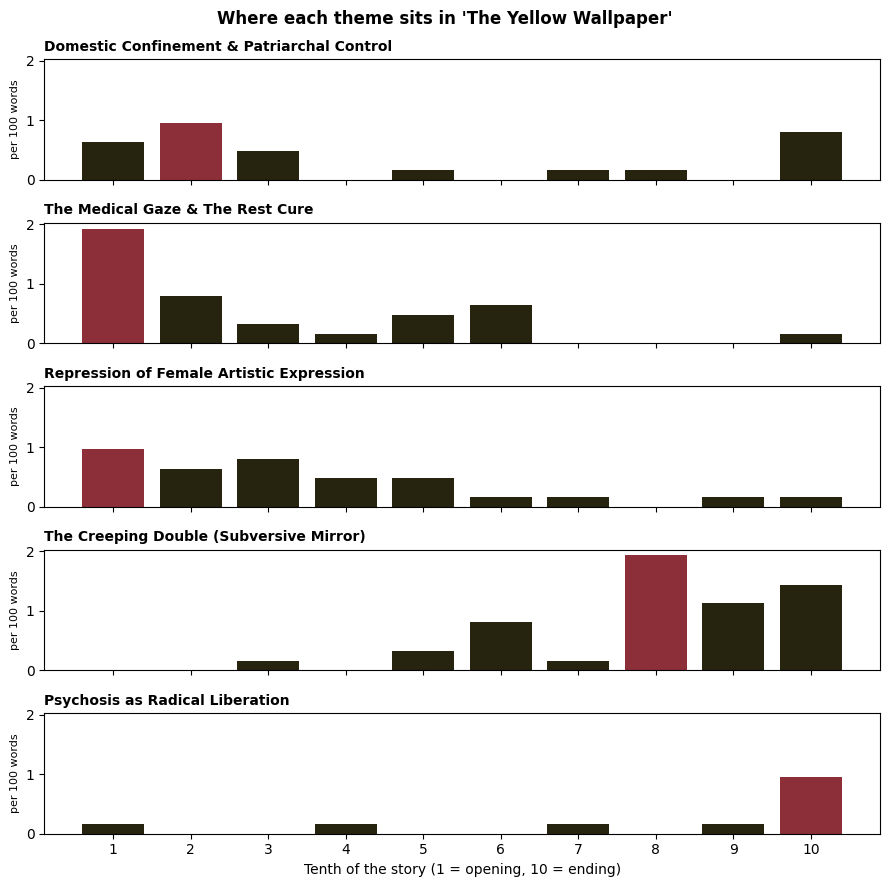

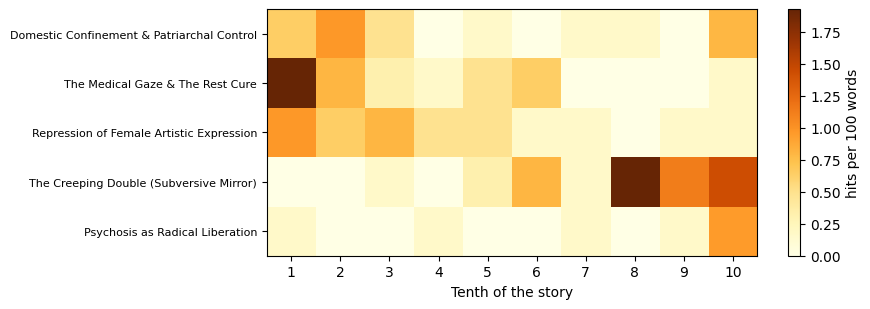

In [8]:
fig, axes = plt.subplots(len(THEMES), 1, figsize=(9, 9), sharex=True, sharey=True)
for ax, (k, v) in zip(axes, THEMES.items()):
    vals = per100[k]
    ax.bar(vals.index, vals.values, color=["#8c2f39" if x == vals.max() else "#26230f" for x in vals.values])
    ax.set_title(v["label"], loc="left", fontsize=10, fontweight="bold")
    ax.set_ylabel("per 100 words", fontsize=8)
axes[-1].set_xticks(range(1, SEG + 1))
axes[-1].set_xlabel("Tenth of the story (1 = opening, 10 = ending)")
fig.suptitle("Where each theme sits in 'The Yellow Wallpaper'", fontweight="bold")
fig.tight_layout()
fig.savefig("outputs/theme_trajectories.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.2))
im = ax.imshow(per100.T.values, aspect="auto", cmap="YlOrBr")
ax.set_yticks(range(len(THEMES))); ax.set_yticklabels([v["label"] for v in THEMES.values()], fontsize=8)
ax.set_xticks(range(SEG)); ax.set_xticklabels(range(1, SEG + 1))
ax.set_xlabel("Tenth of the story"); fig.colorbar(im, label="hits per 100 words")
fig.tight_layout(); fig.savefig("outputs/theme_heatmap.png", dpi=200)
plt.show()

# STEP 7: Interpretation of the Result

**What the step requires.** The interpretation must come from literary and cultural studies theory and criticism, use discipline-specific citations, relate the logical analysis of the result to the initial impression and the query, and fit the research paradigm through which the query was formed.

**What is done.** The text below is written around the numbers computed in Step 6 (they are filled in automatically, so the text cannot drift from the results). Read it critically and change anything you do not agree with.

In [9]:
R, P = RESULTS, per100
INTERPRETATION = f"""
## Interpretation

**Statements.** S1 holds: confinement language falls from {R['conf_first']:.2f} to {R['conf_second']:.2f} hits per 100 words between the first and second half, and medical language from {R['med_first']:.2f} to {R['med_second']:.2f}. S2 holds: creeping-double vocabulary rises with position in the story (rank correlation {R['double_rho']:.2f}). S3 holds: liberation vocabulary is {R['lib_last']:.2f} per 100 words in the last fifth against {R['lib_rest']:.2f} in the first four-fifths.

**The medical gaze.** Medical language is heaviest in the first tenth ({P['medical'].iloc[0]:.2f} per 100 words). In Foucault's terms the story opens inside the clinical gaze: diagnosis, tonics and regimen are reported as settled facts. Hartsock's standpoint theory and Spivak's idea of epistemic violence explain why this matters, because the narrator's own account is overruled by a husband who is also her doctor ("You see he does not believe I am sick!"). As her attention moves to the wallpaper, her own looking replaces the clinic's.

**The double.** Creeping-double vocabulary is almost absent until the middle and peaks in tenth {int(P['double'].idxmax())} ({P['double'].max():.2f}). This fits Gilbert and Gubar's reading of the woman behind the paper as the narrator's double, a figure who becomes clearer as the narrator identifies with her.

**The rupture.** Liberation vocabulary stays near zero until the final tenth ({P['liberation'].iloc[-1]:.2f}), where the narrator peels the paper, says she has "got out at last" and creeps over her fainted husband. Gilman's own account of the story as an attack on the rest cure makes this the reversal of the opening: the medical gaze is now looked at from outside. Whether the ending is freedom or collapse is what the theme title leaves open. Confinement language also returns in the last tenth ({P['confinement'].iloc[-1]:.2f}), when she locks the door and throws away the key, so its fall in the first half is not a steady decline.

## Limitations

The scan has errors that the cleaning fixes only in part, so some matches are missed. Each tenth holds only a few hits, so the trends matter more than any single bar. The word lists are mine, and some words (work, woman, free) have other uses. The 1-10 scores come from one run of one model and are estimates.

## References

Foucault, Michel. *The Birth of the Clinic: An Archaeology of Medical Perception*. Translated by A. M. Sheridan Smith. Tavistock, 1973.
Gilbert, Sandra M., and Susan Gubar. *The Madwoman in the Attic*. Yale University Press, 1979.
Gilman, Charlotte Perkins. "Why I Wrote 'The Yellow Wallpaper'?" *The Forerunner*, October 1913.
Gilman, Charlotte Perkins [Stetson]. "The Yellow Wall-Paper." *The New England Magazine*, January 1892.
Hartsock, Nancy. "The Feminist Standpoint." In *Discovering Reality*, edited by Sandra Harding and Merrill Hintikka. Reidel, 1983.
Spivak, Gayatri Chakravorty. "Can the Subaltern Speak?" In *Marxism and the Interpretation of Culture*, edited by Cary Nelson and Lawrence Grossberg. Macmillan, 1988.
"""
open("outputs/interpretation.md", "w", encoding="utf-8").write(INTERPRETATION)
print(INTERPRETATION)
print("Files in outputs/:", sorted(os.listdir("outputs")))


## Interpretation

**Statements.** S1 holds: confinement language falls from 0.45 to 0.22 hits per 100 words between the first and second half, and medical language from 0.74 to 0.16. S2 holds: creeping-double vocabulary rises with position in the story (rank correlation 0.87). S3 holds: liberation vocabulary is 0.56 per 100 words in the last fifth against 0.06 in the first four-fifths.

**The medical gaze.** Medical language is heaviest in the first tenth (1.93 per 100 words). In Foucault's terms the story opens inside the clinical gaze: diagnosis, tonics and regimen are reported as settled facts. Hartsock's standpoint theory and Spivak's idea of epistemic violence explain why this matters, because the narrator's own account is overruled by a husband who is also her doctor ("You see he does not believe I am sick!"). As her attention moves to the wallpaper, her own looking replaces the clinic's.

**The double.** Creeping-double vocabulary is almost absent until the middle and peaks in